In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
#%load_ext line_profiler
#%load_ext snakeviz
%autoreload 2

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import corner

import pickle

import enterprise
from enterprise.pulsar import Pulsar
import enterprise.signals.parameter as parameter
from enterprise.signals import utils
from enterprise.signals import signal_base
from enterprise.signals import selections
from enterprise.signals.selections import Selection
from enterprise.signals import white_signals
from enterprise.signals import gp_signals
from enterprise.signals import deterministic_signals
import enterprise.constants as const

from enterprise_extensions import deterministic

from scipy.stats import norm

import libstempo as T2
import libstempo.toasim as LT
import libstempo.plot as LP

import glob
import json
import h5py
import healpy as hp
import scipy.constants as sc
import emcee

from numba.typed import List

import sys
import h5py
import os

In [2]:
target_d_L = 317.7#Mpc

In [3]:
filename = "Gondor_detect_corner_plot.pdf"

In [4]:
base = "Gondor_narrow_detection_dL_317.7"
crnr_plt_title1 =base
crnr_plt_title2 =base+'_corner plot_all_params'
trace_plot_title = base+'trace_plot'
BF_histogram_title = base+'log10A_histogram'
BFerr_title = base+'log10A_histogram_error'

In [5]:
pwd

'/scratch/na00078/projects/15yr_narrow_targeted/post_processing/detect'

## Generate Outfile

## Run Outfile

In [6]:
#COMMENT IF OUTFILE GENERATED
#Thinning script for one source
i = "/scratch/na00078/projects/15yr_narrow_targeted/h5_files/gondor_detect_narrow_outfile.h5"
infile = i
first_n_param = 8
# outfile = '/scratch/na00078/QuickCW_targeted_runs/results/3C66B_outfile.h5'

print(infile)
print(first_n_param)

with h5py.File(infile, 'r') as f:
    Ts = f['T-ladder'][...]
    samples_cold = f['samples_cold'][:,:,:first_n_param]
    print(samples_cold[-1].shape)
    log_likelihood = f['log_likelihood'][:1,:]
    print(log_likelihood.shape)
    par_names = [x.decode('UTF-8') for x in list(f['par_names'])]
    acc_fraction = f['acc_fraction'][...]
    fisher_diag = f['fisher_diag'][...]

/scratch/na00078/projects/15yr_narrow_targeted/h5_files/gondor_detect_narrow_outfile.h5
8
(100000000, 8)
(1, 100000000)


## Corner Plots

In [7]:
'''
KPC2S = sc.parsec / sc.c * 1e3
SOLAR2S = sc.G / sc.c ** 3 * 1.98855e30


xxx0 = {"0_cos_gwtheta":np.cos(0.6387905062299246),
       "0_cos_inc":0.8412486994612669,
       "0_gwphi":3.3335788713091694,
       "0_log10_fgw":np.log10(3.7e-09),
       "0_log10_h":-13.668773493298787,
       "0_log10_mc":np.log10(4300000000),
       "phase0": 0.24434609527920614,
        "psi": 1.1187560505283651,
        "distance": 75.4,}


xxx = {
       "0_cos_inc":0.8412486994612669,
        "0_log10_h":-13.668773493298787,
       "0_log10_mc":np.log10(4300000000),
       "phase0": 0.24434609527920614,
        "psi": 1.1187560505283651}

xxx['gwb_gamma'] = np.nan    
xxx['gwb_log10_A'] = -15.070581074285707
    
#print(xxx)

# In[6]:


'''

'\nKPC2S = sc.parsec / sc.c * 1e3\nSOLAR2S = sc.G / sc.c ** 3 * 1.98855e30\n\n\nxxx0 = {"0_cos_gwtheta":np.cos(0.6387905062299246),\n       "0_cos_inc":0.8412486994612669,\n       "0_gwphi":3.3335788713091694,\n       "0_log10_fgw":np.log10(3.7e-09),\n       "0_log10_h":-13.668773493298787,\n       "0_log10_mc":np.log10(4300000000),\n       "phase0": 0.24434609527920614,\n        "psi": 1.1187560505283651,\n        "distance": 75.4,}\n\n\nxxx = {\n       "0_cos_inc":0.8412486994612669,\n        "0_log10_h":-13.668773493298787,\n       "0_log10_mc":np.log10(4300000000),\n       "phase0": 0.24434609527920614,\n        "psi": 1.1187560505283651}\n\nxxx[\'gwb_gamma\'] = np.nan    \nxxx[\'gwb_log10_A\'] = -15.070581074285707\n    \n#print(xxx)\n\n# In[6]:\n\n\n'

hamp [2.2562234e-18 1.2099236e-17 5.7063217e-16 ... 4.1115543e-15 4.6807943e-15
 4.6807943e-15]
freq [1.4399997e-08 1.4399997e-08 1.4399997e-08 ... 1.4399997e-08 1.4399997e-08
 1.4399997e-08]
mc [7.959112e+07 3.290544e+07 3.290544e+07 ... 9.882143e+09 9.882143e+09
 9.882143e+09]
Length of logdL 100000000
required values 8.547869 1.4399997e-08 32905440.0 8.5783355e-15
dL min 314.52299999999997
dL max 320.877
10**log10_d_L [2.2958188e+03 9.8227570e+01 2.0827403e+00 ... 3.8930593e+03 3.4196174e+03
 3.4196174e+03]
min 10**log10_d_L 0.0126859285
max 10**log10_d_L 353076400.0
d_L_mask [   19114    21788    21843 ... 99996303 99996632 99996731]
notd_L_mask1 [       1        2        3 ... 99996997 99996998 99996999]
notd_L_mask2 [       0     9008     9034 ... 99999997 99999998 99999999]
merged_non_dL [       1        2        3 ... 99999997 99999998 99999999]
Sample shape (100000000, 9)
dL_mask length 219291
5


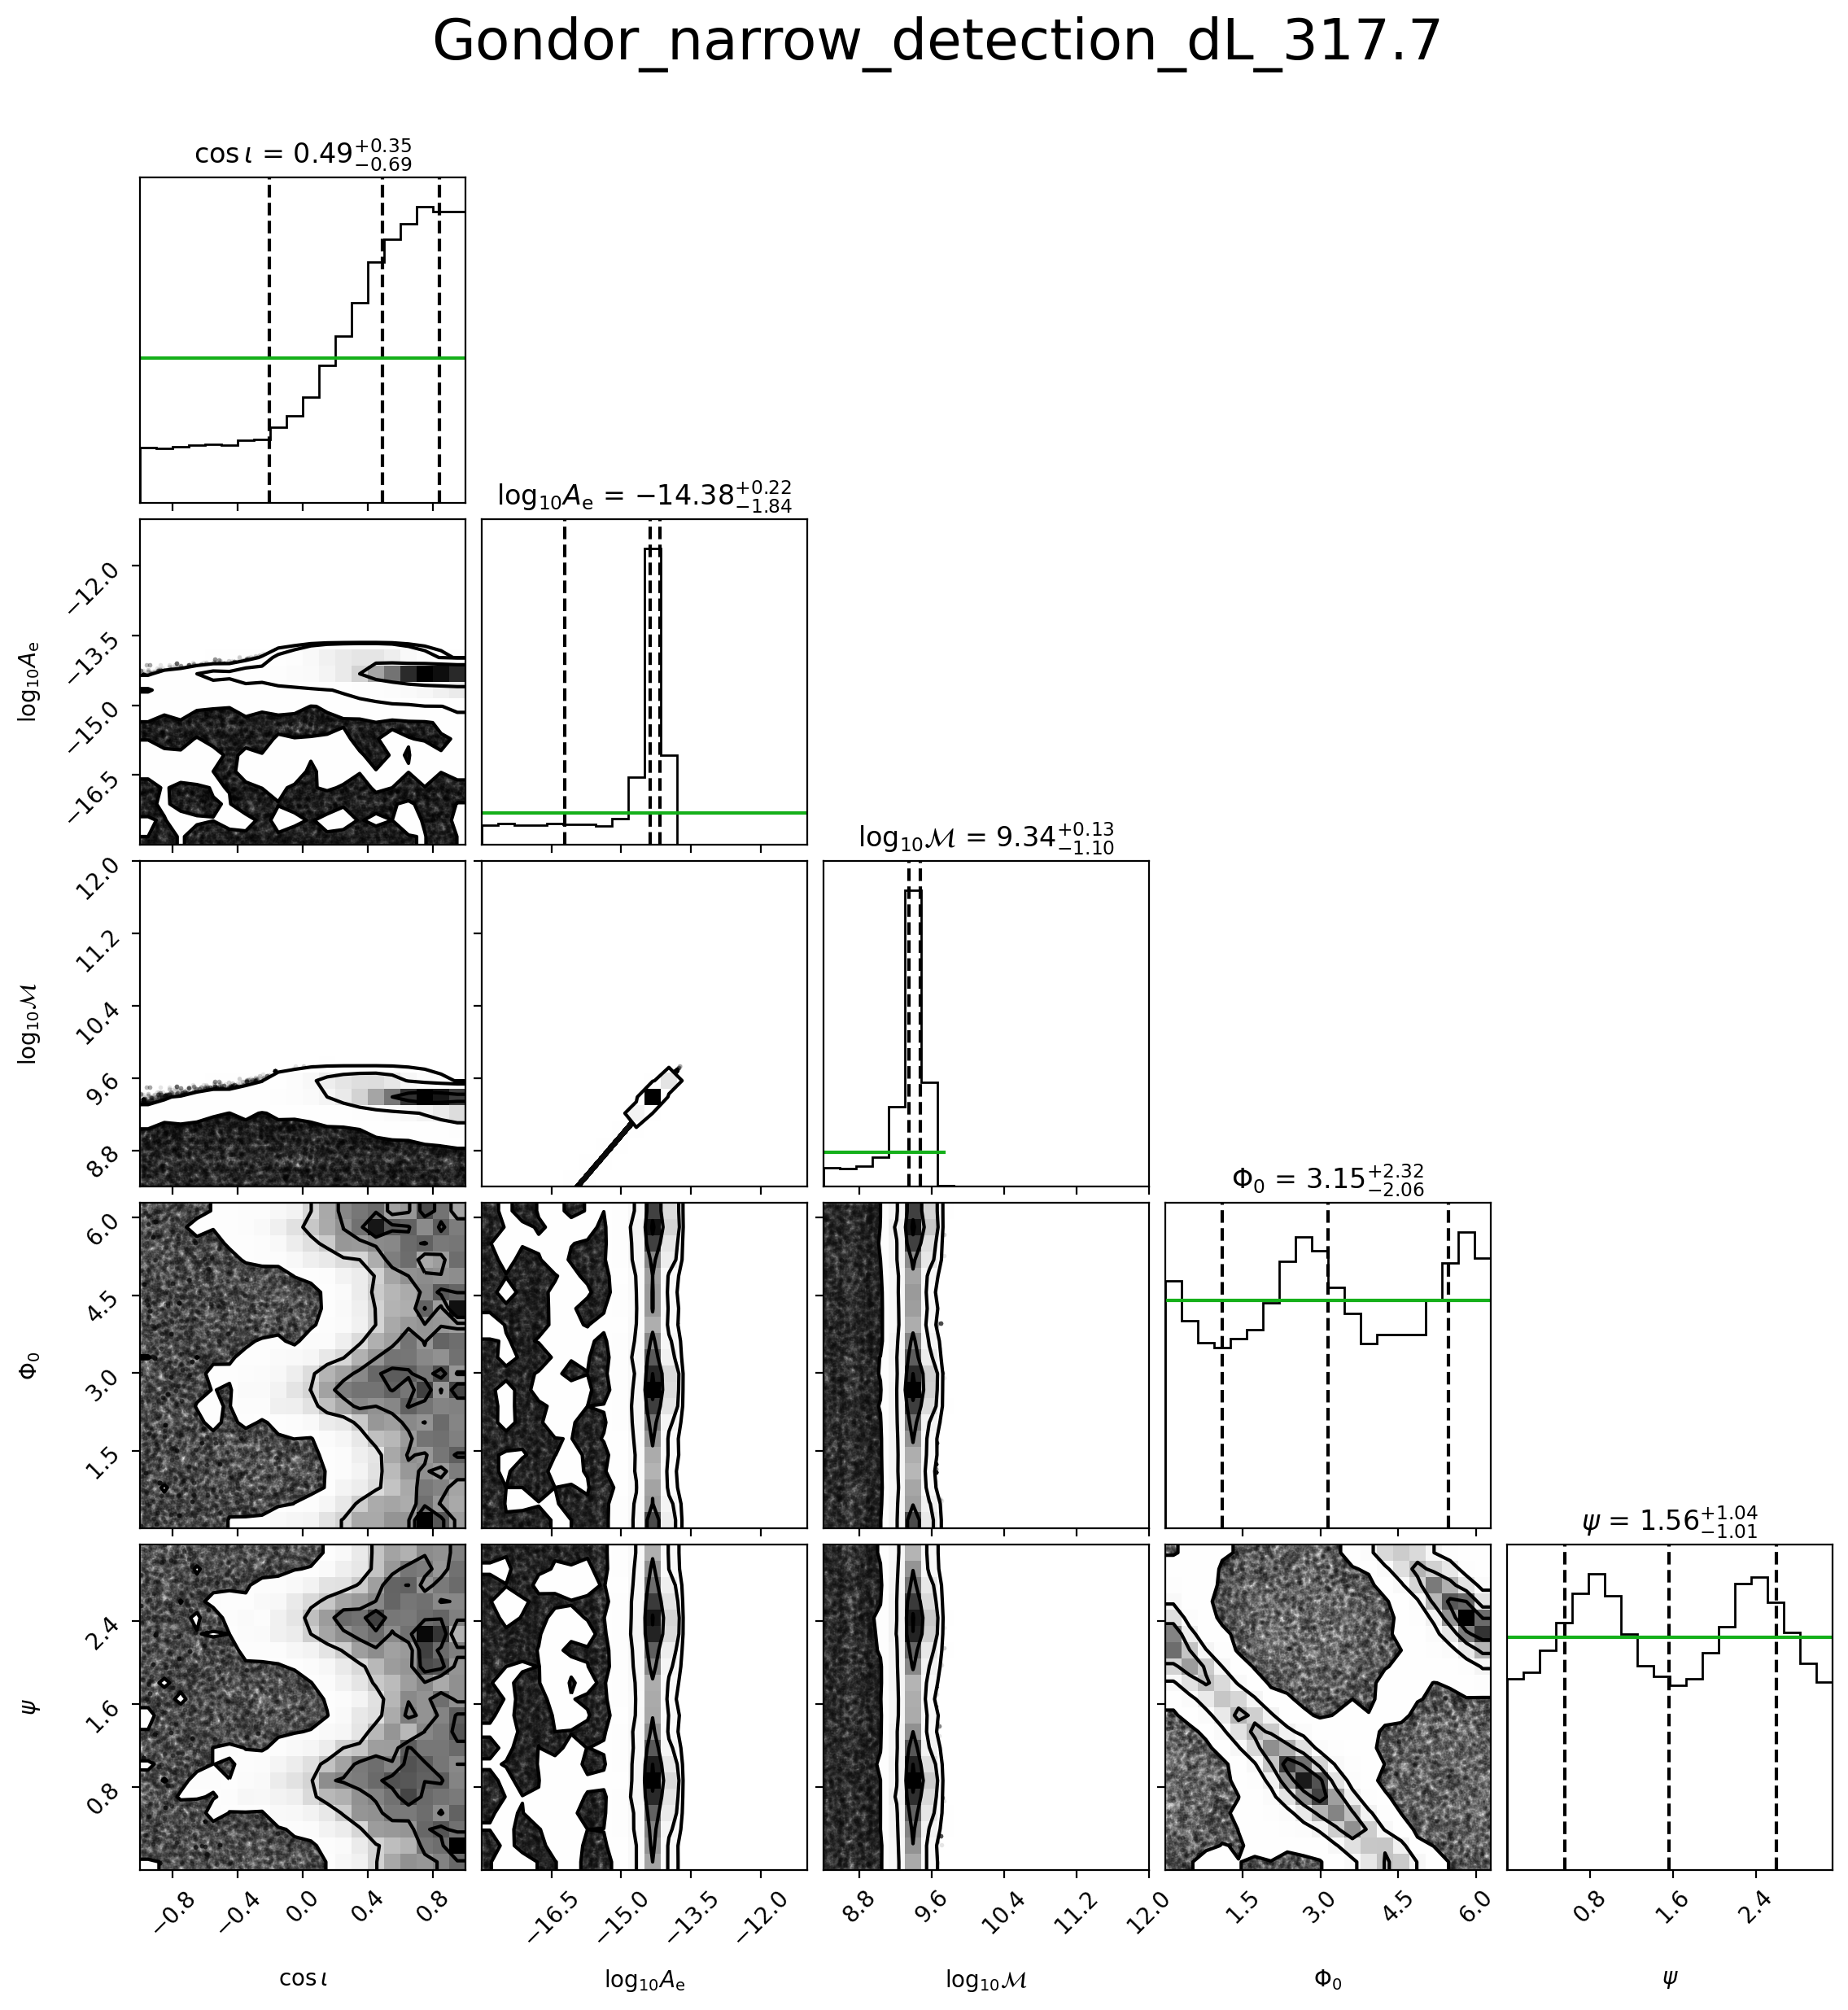

In [8]:
#corner plot of parameters common to all pulsars (Contains Luminosity distance)
corner_mask = [0, 1, 2, 3, 4, 5, 6, 7]
par_keys = ["0_cos_gwtheta", "0_cos_inc", "0_gwphi", "0_log10_fgw",
          "0_log10_h", "0_log10_mc", "0_phase0", "0_psi","log10_d_L"]
#labels = [r"$\cos \theta$", r"$\cos \iota$", r"$\phi$", r"$\log_{10} f_{\rm GW}$",
      #    r"$\log_{10} A_{\rm e}$", r"$\log_{10} {\cal M}$", r"$\Phi_0$", r"$\psi$",r"$\log_{10} d_L$"]
labels = [r"$\cos \iota$", r"$\log_{10} A_{\rm e}$", r"$\log_{10} {\cal M}$", r"$\Phi_0$",r"$\psi$"]


#set burnin and thinning
#burnin = 0
#burnin = 500_000
burnin = 0#int(1e6)
thin = 1

#set ranges
ranges = [(-1,1), (-18,-11), (8.40,12), (0,2*np.pi), (0,np.pi)]
#ranges = [(-1,1), (-1,1), (0,2*np.pi), (-8.704,np.log10(3e-7)), (-18,-11), (6.6,12), (0,2*np.pi), (0,np.pi), (0,10)]
#ranges = [0.99]*9


megaparsec = 3.086e+22 #meter
speed_of_light = 299792458.0 #m/s
T_sun = 1.327124400e20 / speed_of_light**3 #G*M_sun/c^3 = R_sun/c-->Sun time

############################################################################
h_amp = 10**samples_cold[0][burnin::thin,4]
fff = 10**samples_cold[0][burnin::thin,3]
mmm = 10**samples_cold[0][burnin::thin,5]

print('hamp',h_amp)
print('freq',fff)
print('mc',mmm)

log10_d_L = np.log10(2 * (mmm*T_sun)**(5/3) * (np.pi*fff)**(2/3) / h_amp *speed_of_light/megaparsec)
print("Length of logdL", len(log10_d_L))
print("required values",np.max(log10_d_L), fff[1000], mmm[1000], h_amp[1000] )
#####################################

d_L_percent_tolerance = 1.0
#####################################

d_L_min = target_d_L*(1-d_L_percent_tolerance/100)
d_L_max = target_d_L*(1+d_L_percent_tolerance/100)
print("dL min",d_L_min)
print("dL max",d_L_max)
print("10**log10_d_L",10**log10_d_L)
print("min 10**log10_d_L",np.min(10**log10_d_L))
print("max 10**log10_d_L",np.max(10**log10_d_L))

d_L_mask = np.where((10**log10_d_L>=d_L_min) & (10**log10_d_L<=d_L_max))[0]
print("d_L_mask",d_L_mask)

#########################
not_d_L_mask_1 = np.where((10**log10_d_L<d_L_min))[0] #& (10**log10_d_L>d_L_max))[0]
print("notd_L_mask1",not_d_L_mask_1)
not_d_L_mask_2 = np.where((10**log10_d_L>d_L_max))[0] #& ())[0]
print("notd_L_mask2",not_d_L_mask_2)

merged_non_dL = np.concatenate((not_d_L_mask_1,not_d_L_mask_2))
print("merged_non_dL",merged_non_dL)
########################################

samples2plot = np.concatenate((samples_cold[0][burnin::thin,corner_mask], np.array([log10_d_L,]).T), axis=1)

print("Sample shape", samples2plot.shape)
print("dL_mask length", len(d_L_mask))
print(len(ranges))

samples2plot_detect = np.vstack((
                          samples2plot[d_L_mask,1],
                          samples2plot[d_L_mask,4],
                          samples2plot[d_L_mask,5],
                          samples2plot[d_L_mask,6],
                          samples2plot[d_L_mask,7])).T


fig = corner.corner(samples2plot_detect,
                    labels=labels,
                    show_titles=True, quantiles=[0.16, 0.5, 0.84],
                    range=ranges, hist_kwargs={"density":True})

#plot priors over 1D posteriors
for i, ax in enumerate(fig.axes):
    if i==0:#(len(labels)+1): #cos inc and cos theta
        Xs = np.linspace(-1,1)
        ax.plot(Xs, Xs*0+1/2, color="xkcd:green")
    #elif i==3*(len(labels)+1): #log10_fgw
     #   Xs = np.linspace(np.log10(3.5e-9), -7.0)
        # Y = plot_Gaussian(Xs,np.log10(1.13e-8),1)
        # ax.plot(Xs,Y, color='xkcd:green')
      #  ax.plot(Xs, Xs*0+1/(np.log10(3e-7)+8.704), color="xkcd:green")
    elif i==(len(labels)+1): #log10_A
        Xs = np.linspace(-18, -11)
        ax.plot(Xs, Xs*0+1/7, color="xkcd:green")
    elif i==2*(len(labels)+1): #log10_M_ch
        Xs = np.linspace(np.min(samples2plot[d_L_mask,5]), np.max(samples2plot[d_L_mask,5]))
        # Y=plot_Gaussian(Xs,9.86,1)
        # ax.plot(Xs,Y, color='xkcd:green')
        ax.plot(Xs, Xs*0+1/3, color="xkcd:green")
    elif i==3*(len(labels)+1): #gwphi and phase0
        Xs = np.linspace(0,2*np.pi)
        ax.plot(Xs, Xs*0+1/(2*np.pi), color="xkcd:green")
    elif i==4*(len(labels)+1): #psi
        Xs = np.linspace(0,np.pi)
        ax.plot(Xs, Xs*0+1/np.pi, color="xkcd:green")

fig.suptitle(crnr_plt_title1, fontsize = 25,y=1.05);

Corner plot saved to /scratch/na00078/projects/15yr_narrow_targeted/post_processing/figures/detect/Gondor_detect_corner_plot.pdf


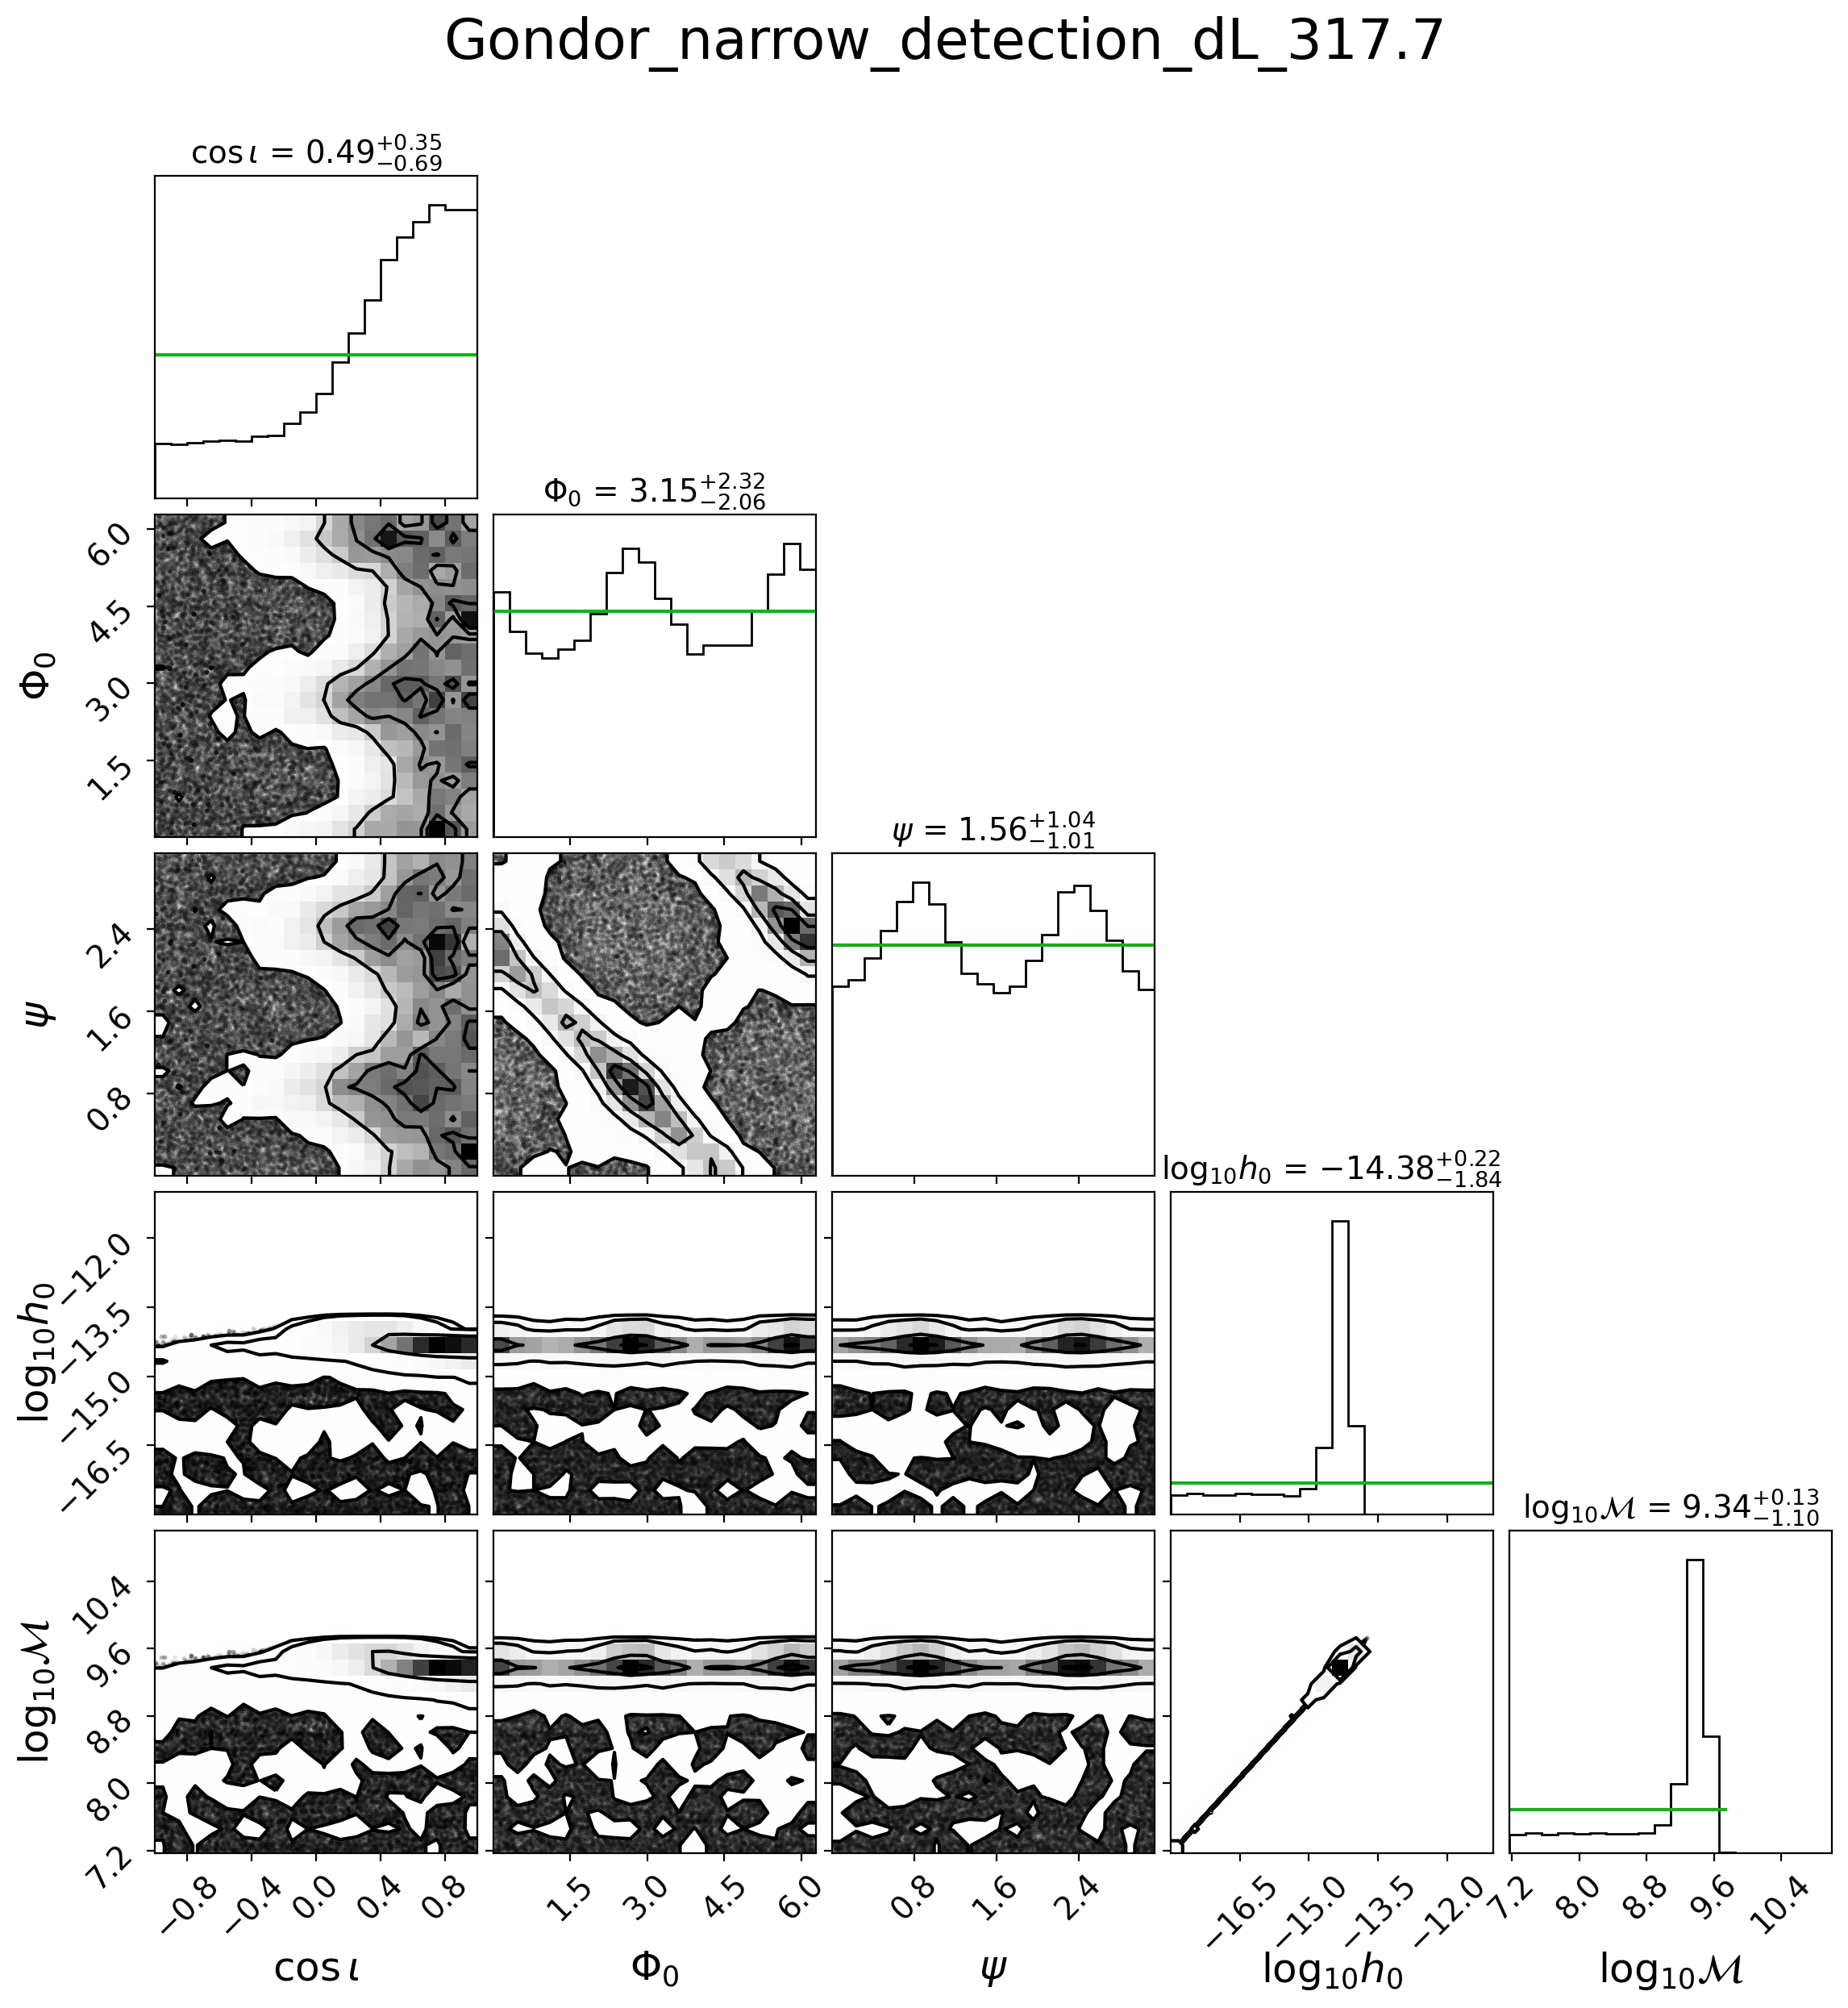

In [9]:
 import numpy as np
import corner

# corner plot of parameters common to all pulsars (Contains Luminosity distance)
corner_mask = [0, 1, 2, 3, 4, 5, 6, 7]
par_keys = ["0_cos_gwtheta", "0_cos_inc", "0_gwphi", "0_log10_fgw",
            "0_log10_h", "0_log10_mc", "0_phase0", "0_psi","log10_d_L"]

# New label order: cos i, phi0, psi, log10 h, log10 Mc
labels = [
    r"$\cos \iota$",          # cos inc
    r"$\Phi_0$",              # phase0
    r"$\psi$",                # psi
    r"$\log_{10} h_{0}$", # log10 h
    r"$\log_{10} {\cal M}$"   # chirp mass
]

# Set ranges in the same order
ranges = [
    (-1, 1),          # cos i
    (0, 2*np.pi),     # phase0
    (0, np.pi),       # psi
    (-18, -11),       # log10 h
    (7.17, 11)        # log10 Mc
]

# burnin/thinning
burnin = 0
thin = 1

# constants
megaparsec = 3.086e+22 # meter
speed_of_light = 299792458.0 # m/s
T_sun = 1.327124400e20 / speed_of_light**3 # G*M_sun/c^3

############################################################################
h_amp = 10**samples_cold[0][burnin::thin,4]
fff   = 10**samples_cold[0][burnin::thin,3]
mmm   = 10**samples_cold[0][burnin::thin,5]

log10_d_L = np.log10(2 * (mmm*T_sun)**(5/3) * (np.pi*fff)**(2/3) / h_amp * speed_of_light/megaparsec)

d_L_percent_tolerance = 1.0
d_L_min = target_d_L*(1-d_L_percent_tolerance/100)
d_L_max = target_d_L*(1+d_L_percent_tolerance/100)

d_L_mask = np.where((10**log10_d_L>=d_L_min) & (10**log10_d_L<=d_L_max))[0]

# collect samples for plotting
samples2plot = np.concatenate(
    (samples_cold[0][burnin::thin,corner_mask], np.array([log10_d_L,]).T), axis=1
)

samples2plot_detect = np.vstack((
    samples2plot[d_L_mask, 1],  # cos inc
    samples2plot[d_L_mask, 6],  # phase0
    samples2plot[d_L_mask, 7],  # psi
    samples2plot[d_L_mask, 4],  # log10 h
    samples2plot[d_L_mask, 5]   # log10 Mc
)).T

# Make corner plot
fig = corner.corner(samples2plot_detect,
                    labels=labels,
                    show_titles=True,
                    range=ranges,
                    hist_kwargs={"density": True},label_kwargs={"fontsize": 18},   # increase axis label font size
    title_kwargs={"fontsize": 14} )

# Overlay priors in the right order
for i, ax in enumerate(fig.axes):
    if i == 0:  # cos i prior (uniform -1,1)
        Xs = np.linspace(-1, 1)
        ax.plot(Xs, Xs*0 + 0.5, color="xkcd:green")

    elif i == (len(labels)+1):  # phi0 prior (uniform 0, 2π)
        Xs = np.linspace(0, 2*np.pi)
        ax.plot(Xs, Xs*0 + 1/(2*np.pi), color="xkcd:green")

    elif i == 2*(len(labels)+1):  # psi prior (uniform 0, π)
        Xs = np.linspace(0, np.pi)
        ax.plot(Xs, Xs*0 + 1/np.pi, color="xkcd:green")

    elif i == 3*(len(labels)+1):  # log10 h prior (uniform)
        Xs = np.linspace(-18, -11)
        ax.plot(Xs, Xs*0 + 1/7, color="xkcd:green")

    elif i == 4*(len(labels)+1):  # log10 Mc prior (broad uniform approx)
        Xs = np.linspace(np.min(samples2plot[d_L_mask,5]),
                         np.max(samples2plot[d_L_mask,5]))
        ax.plot(Xs, Xs*0 + 1/3, color="xkcd:green")

fig.suptitle(crnr_plt_title1, fontsize=25, y=1.05)

# Make tick labels a bit larger too
for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=14)

# Define output directory and filename
outdir = "/scratch/na00078/projects/15yr_narrow_targeted/post_processing/figures/detect"


# Make sure directory exists
os.makedirs(outdir, exist_ok=True)

# Save figure
outpath = os.path.join(outdir, filename)
fig.savefig(outpath, bbox_inches="tight", dpi=300)

print(f"Corner plot saved to {outpath}")

hamp [2.2562234e-18 1.2099236e-17 5.7063217e-16 ... 4.1115543e-15 4.6807943e-15
 4.6807943e-15]
freq [1.4399997e-08 1.4399997e-08 1.4399997e-08 ... 1.4399997e-08 1.4399997e-08
 1.4399997e-08]
mc [7.959112e+07 3.290544e+07 3.290544e+07 ... 9.882143e+09 9.882143e+09
 9.882143e+09]
Length of logdL 100000000
required values 8.547869e+00 1.4399997e-08 32905440.0 8.5783355e-15
dL min 314.52299999999997
dL max 320.877
10**log10_d_L [2.2958188e+03 9.8227570e+01 2.0827403e+00 ... 3.8930593e+03 3.4196174e+03
 3.4196174e+03]
min 10**log10_d_L 0.0126859285
max 10**log10_d_L 353076400.0
d_L_mask [   19114    21788    21843 ... 99996303 99996632 99996731]
notd_L_mask1 [       1        2        3 ... 99996997 99996998 99996999]
notd_L_mask2 [       0     9008     9034 ... 99999997 99999998 99999999]
merged_non_dL [       1        2        3 ... 99999997 99999998 99999999]
Sample shape (100000000, 9)
dL_mask length 219291
9


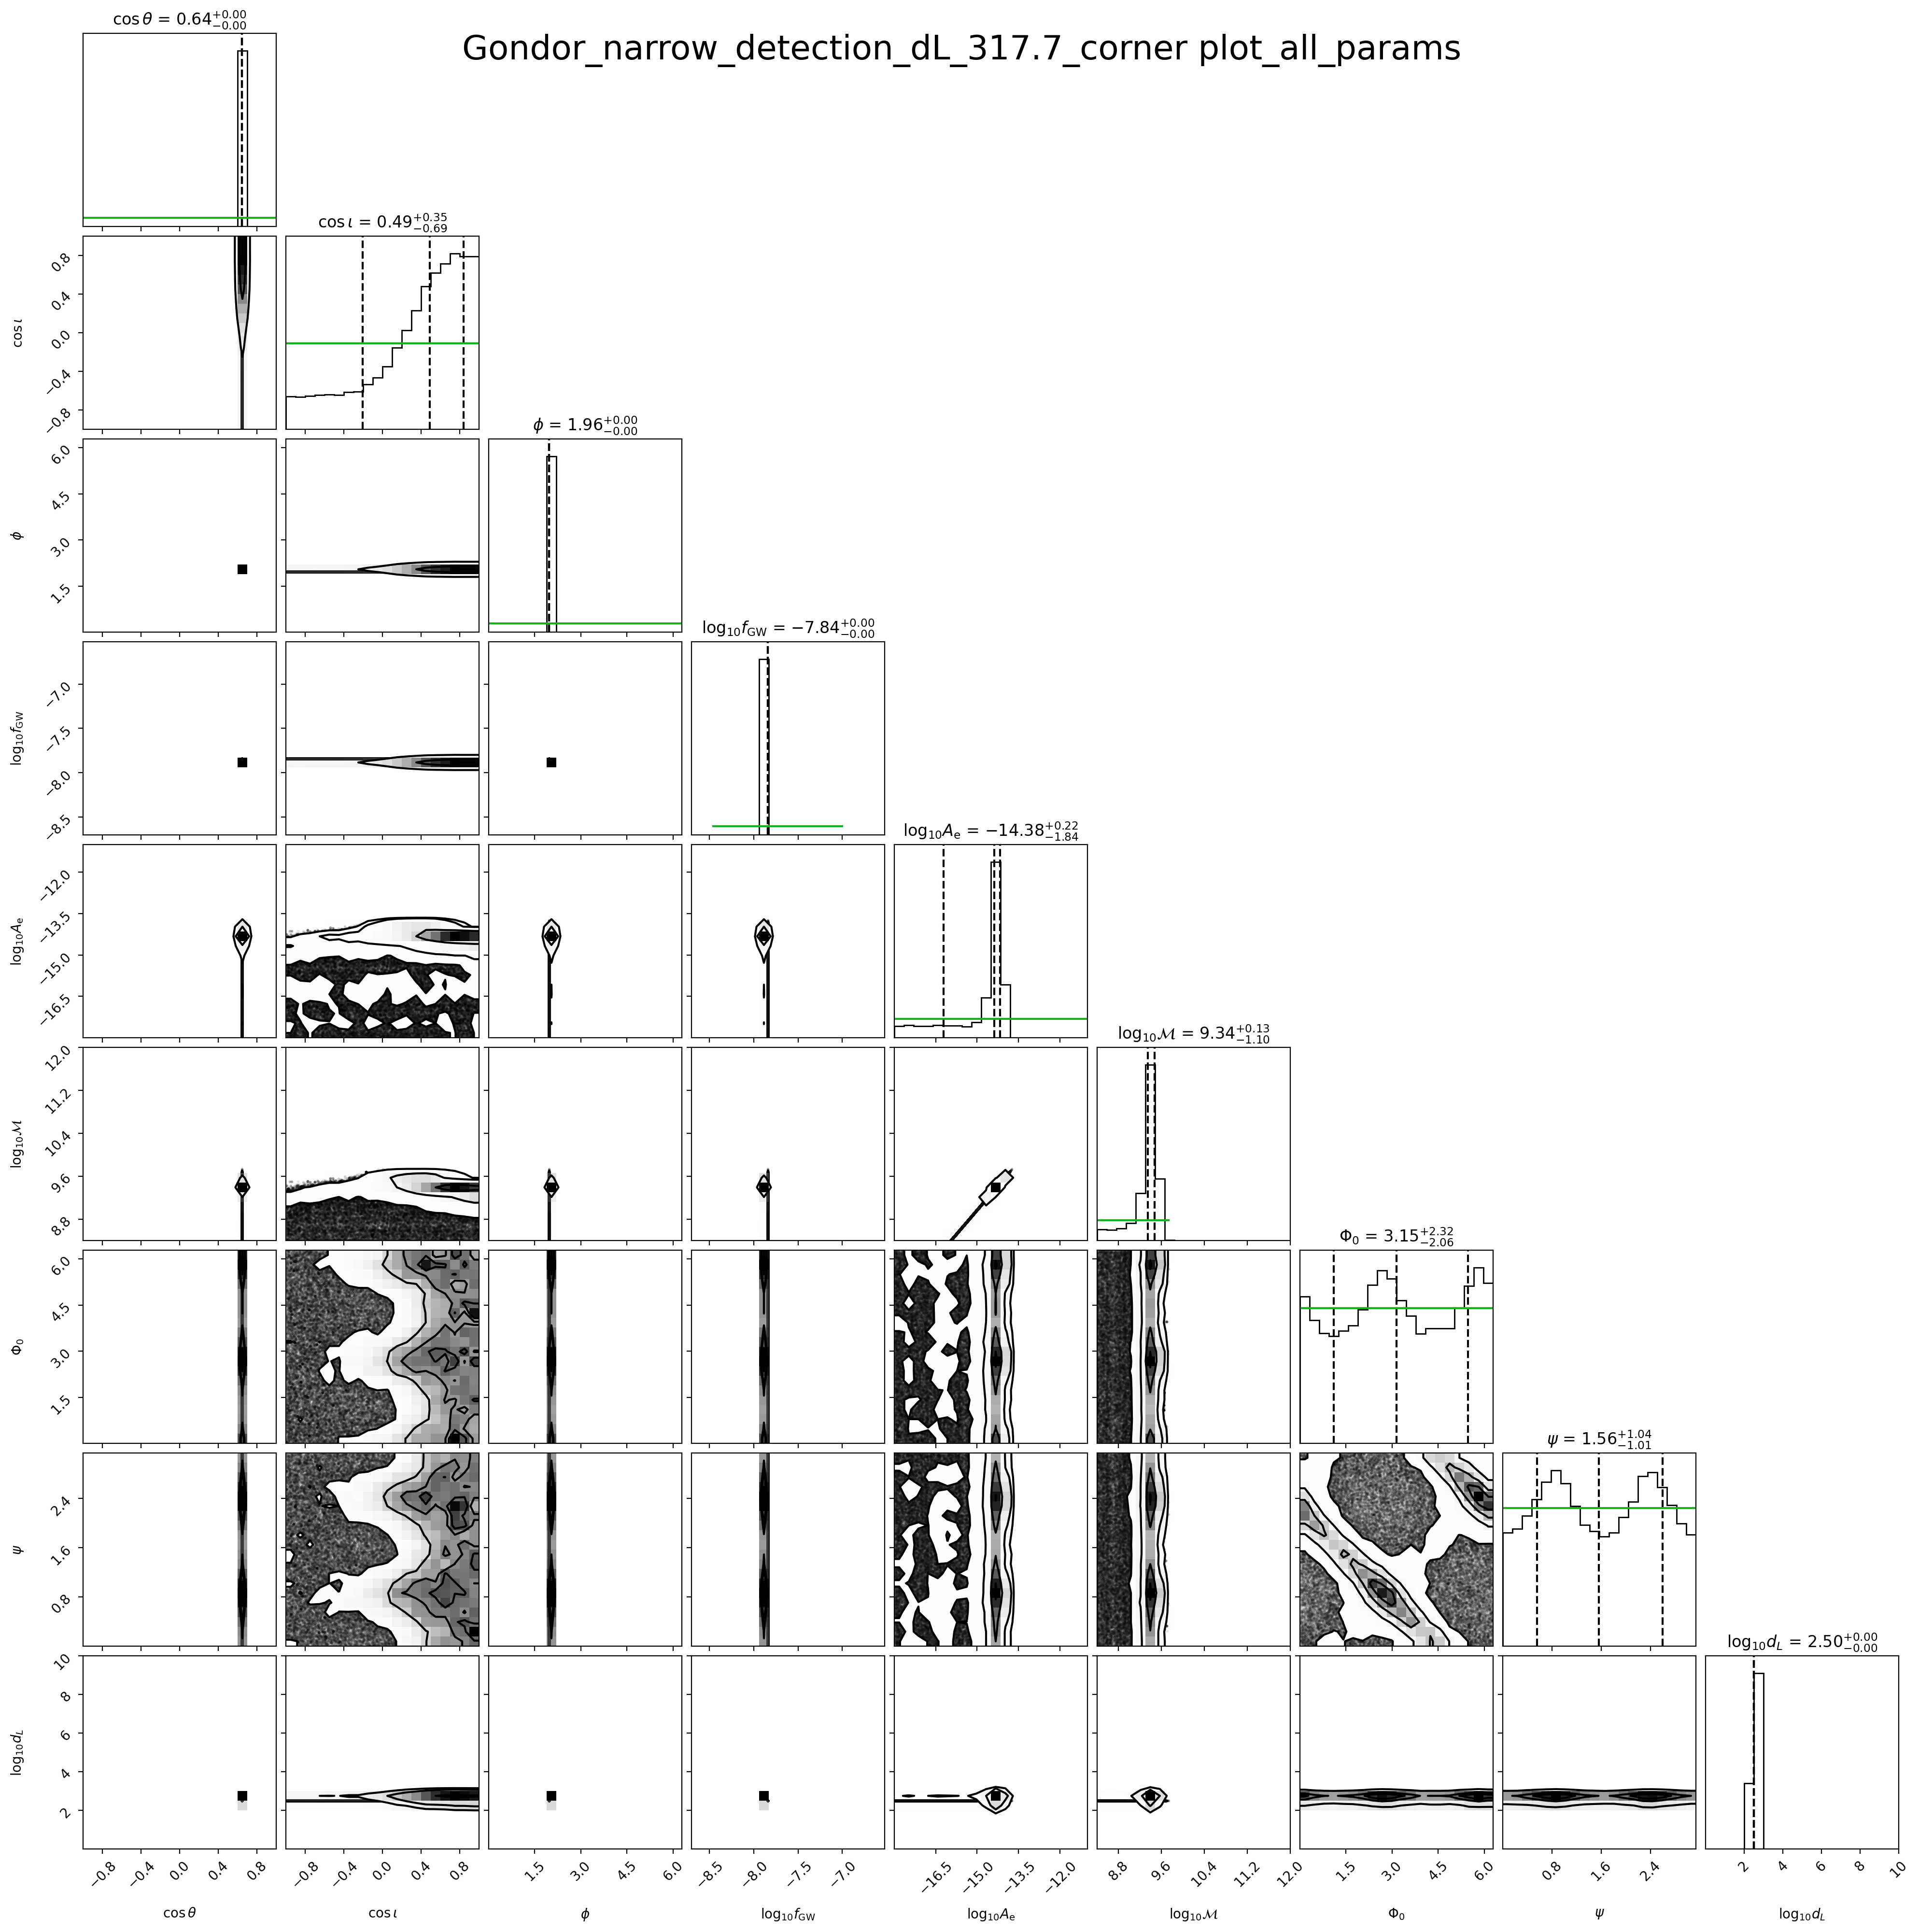

In [10]:
#corner plot of parameters common to all pulsars (Contains Luminosity distance)
corner_mask = [0, 1, 2, 3, 4, 5, 6, 7]
par_keys = ["0_cos_gwtheta", "0_cos_inc", "0_gwphi", "0_log10_fgw",
          "0_log10_h", "0_log10_mc", "0_phase0", "0_psi","log10_d_L"]
labels = [r"$\cos \theta$", r"$\cos \iota$", r"$\phi$", r"$\log_{10} f_{\rm GW}$",
          r"$\log_{10} A_{\rm e}$", r"$\log_{10} {\cal M}$", r"$\Phi_0$", r"$\psi$",r"$\log_{10} d_L$"]

#set burnin and thinning
#burnin = 0
#burnin = 500_000
burnin = 0#int(1e6)
thin = 1

#set ranges
ranges = [(-1,1), (-1,1), (0,2*np.pi), (-8.704,np.log10(3e-7)), (-18,-11), (8.40,12), (0,2*np.pi), (0,np.pi), (0,10)]
#ranges = [0.99]*9


megaparsec = 3.086e+22 #meter
speed_of_light = 299792458.0 #m/s
T_sun = 1.327124400e20 / speed_of_light**3 #G*M_sun/c^3 = R_sun/c-->Sun time

############################################################################
h_amp = 10**samples_cold[0][burnin::thin,4]
fff = 10**samples_cold[0][burnin::thin,3]
mmm = 10**samples_cold[0][burnin::thin,5]

print('hamp',h_amp)
print('freq',fff)
print('mc',mmm)

log10_d_L = np.log10(2 * (mmm*T_sun)**(5/3) * (np.pi*fff)**(2/3) / h_amp *speed_of_light/megaparsec)
print("Length of logdL", len(log10_d_L))
print("required values",np.max(log10_d_L), fff[1000], mmm[1000], h_amp[1000] )
#####################################
d_L_percent_tolerance = 1.0
#####################################

d_L_min = target_d_L*(1-d_L_percent_tolerance/100)
d_L_max = target_d_L*(1+d_L_percent_tolerance/100)
print("dL min",d_L_min)
print("dL max",d_L_max)
print("10**log10_d_L",10**log10_d_L)
print("min 10**log10_d_L",np.min(10**log10_d_L))
print("max 10**log10_d_L",np.max(10**log10_d_L))

d_L_mask = np.where((10**log10_d_L>=d_L_min) & (10**log10_d_L<=d_L_max))[0]
print("d_L_mask",d_L_mask)

#########################
not_d_L_mask_1 = np.where((10**log10_d_L<d_L_min))[0] #& (10**log10_d_L>d_L_max))[0]
print("notd_L_mask1",not_d_L_mask_1)
not_d_L_mask_2 = np.where((10**log10_d_L>d_L_max))[0] #& ())[0]
print("notd_L_mask2",not_d_L_mask_2)

merged_non_dL = np.concatenate((not_d_L_mask_1,not_d_L_mask_2))
print("merged_non_dL",merged_non_dL)
########################################

samples2plot = np.concatenate((samples_cold[0][burnin::thin,corner_mask], np.array([log10_d_L,]).T), axis=1)

print("Sample shape", samples2plot.shape)
print("dL_mask length", len(d_L_mask))
print(len(ranges))
fig = corner.corner(samples2plot[d_L_mask, :],
                    labels=labels,
                    show_titles=True, quantiles=[0.16, 0.5, 0.84],
                    range=ranges, hist_kwargs={"density":True})

#plot priors over 1D posteriors
for i, ax in enumerate(fig.axes):
    if i==0 or i==(len(labels)+1): #cos inc and cos theta
        Xs = np.linspace(-1,1)
        ax.plot(Xs, Xs*0+1/2, color="xkcd:green")
    elif i==2*(len(labels)+1) or i==6*(len(labels)+1): #gwphi and phase0
        Xs = np.linspace(0,2*np.pi)
        ax.plot(Xs, Xs*0+1/(2*np.pi), color="xkcd:green")
    elif i==3*(len(labels)+1): #log10_fgw
        Xs = np.linspace(np.log10(3.5e-9), -7.0)
        # Y = plot_Gaussian(Xs,np.log10(1.13e-8),1)
        # ax.plot(Xs,Y, color='xkcd:green')
        ax.plot(Xs, Xs*0+1/(np.log10(3e-7)+8.704), color="xkcd:green")
    elif i==4*(len(labels)+1): #log10_A
        Xs = np.linspace(-18, -11)
        ax.plot(Xs, Xs*0+1/7, color="xkcd:green")
    elif i==5*(len(labels)+1): #log10_M_ch
        Xs = np.linspace(np.min(samples2plot[d_L_mask,5]), np.max(samples2plot[d_L_mask,5]))
        # Y=plot_Gaussian(Xs,9.86,1)
        # ax.plot(Xs,Y, color='xkcd:green')
        ax.plot(Xs, Xs*0+1/3, color="xkcd:green")
    elif i==7*(len(labels)+1): #psi
        Xs = np.linspace(0,np.pi)
        ax.plot(Xs, Xs*0+1/np.pi, color="xkcd:green")

        
fig.suptitle(crnr_plt_title2, fontsize = 25);

## Trace Plots

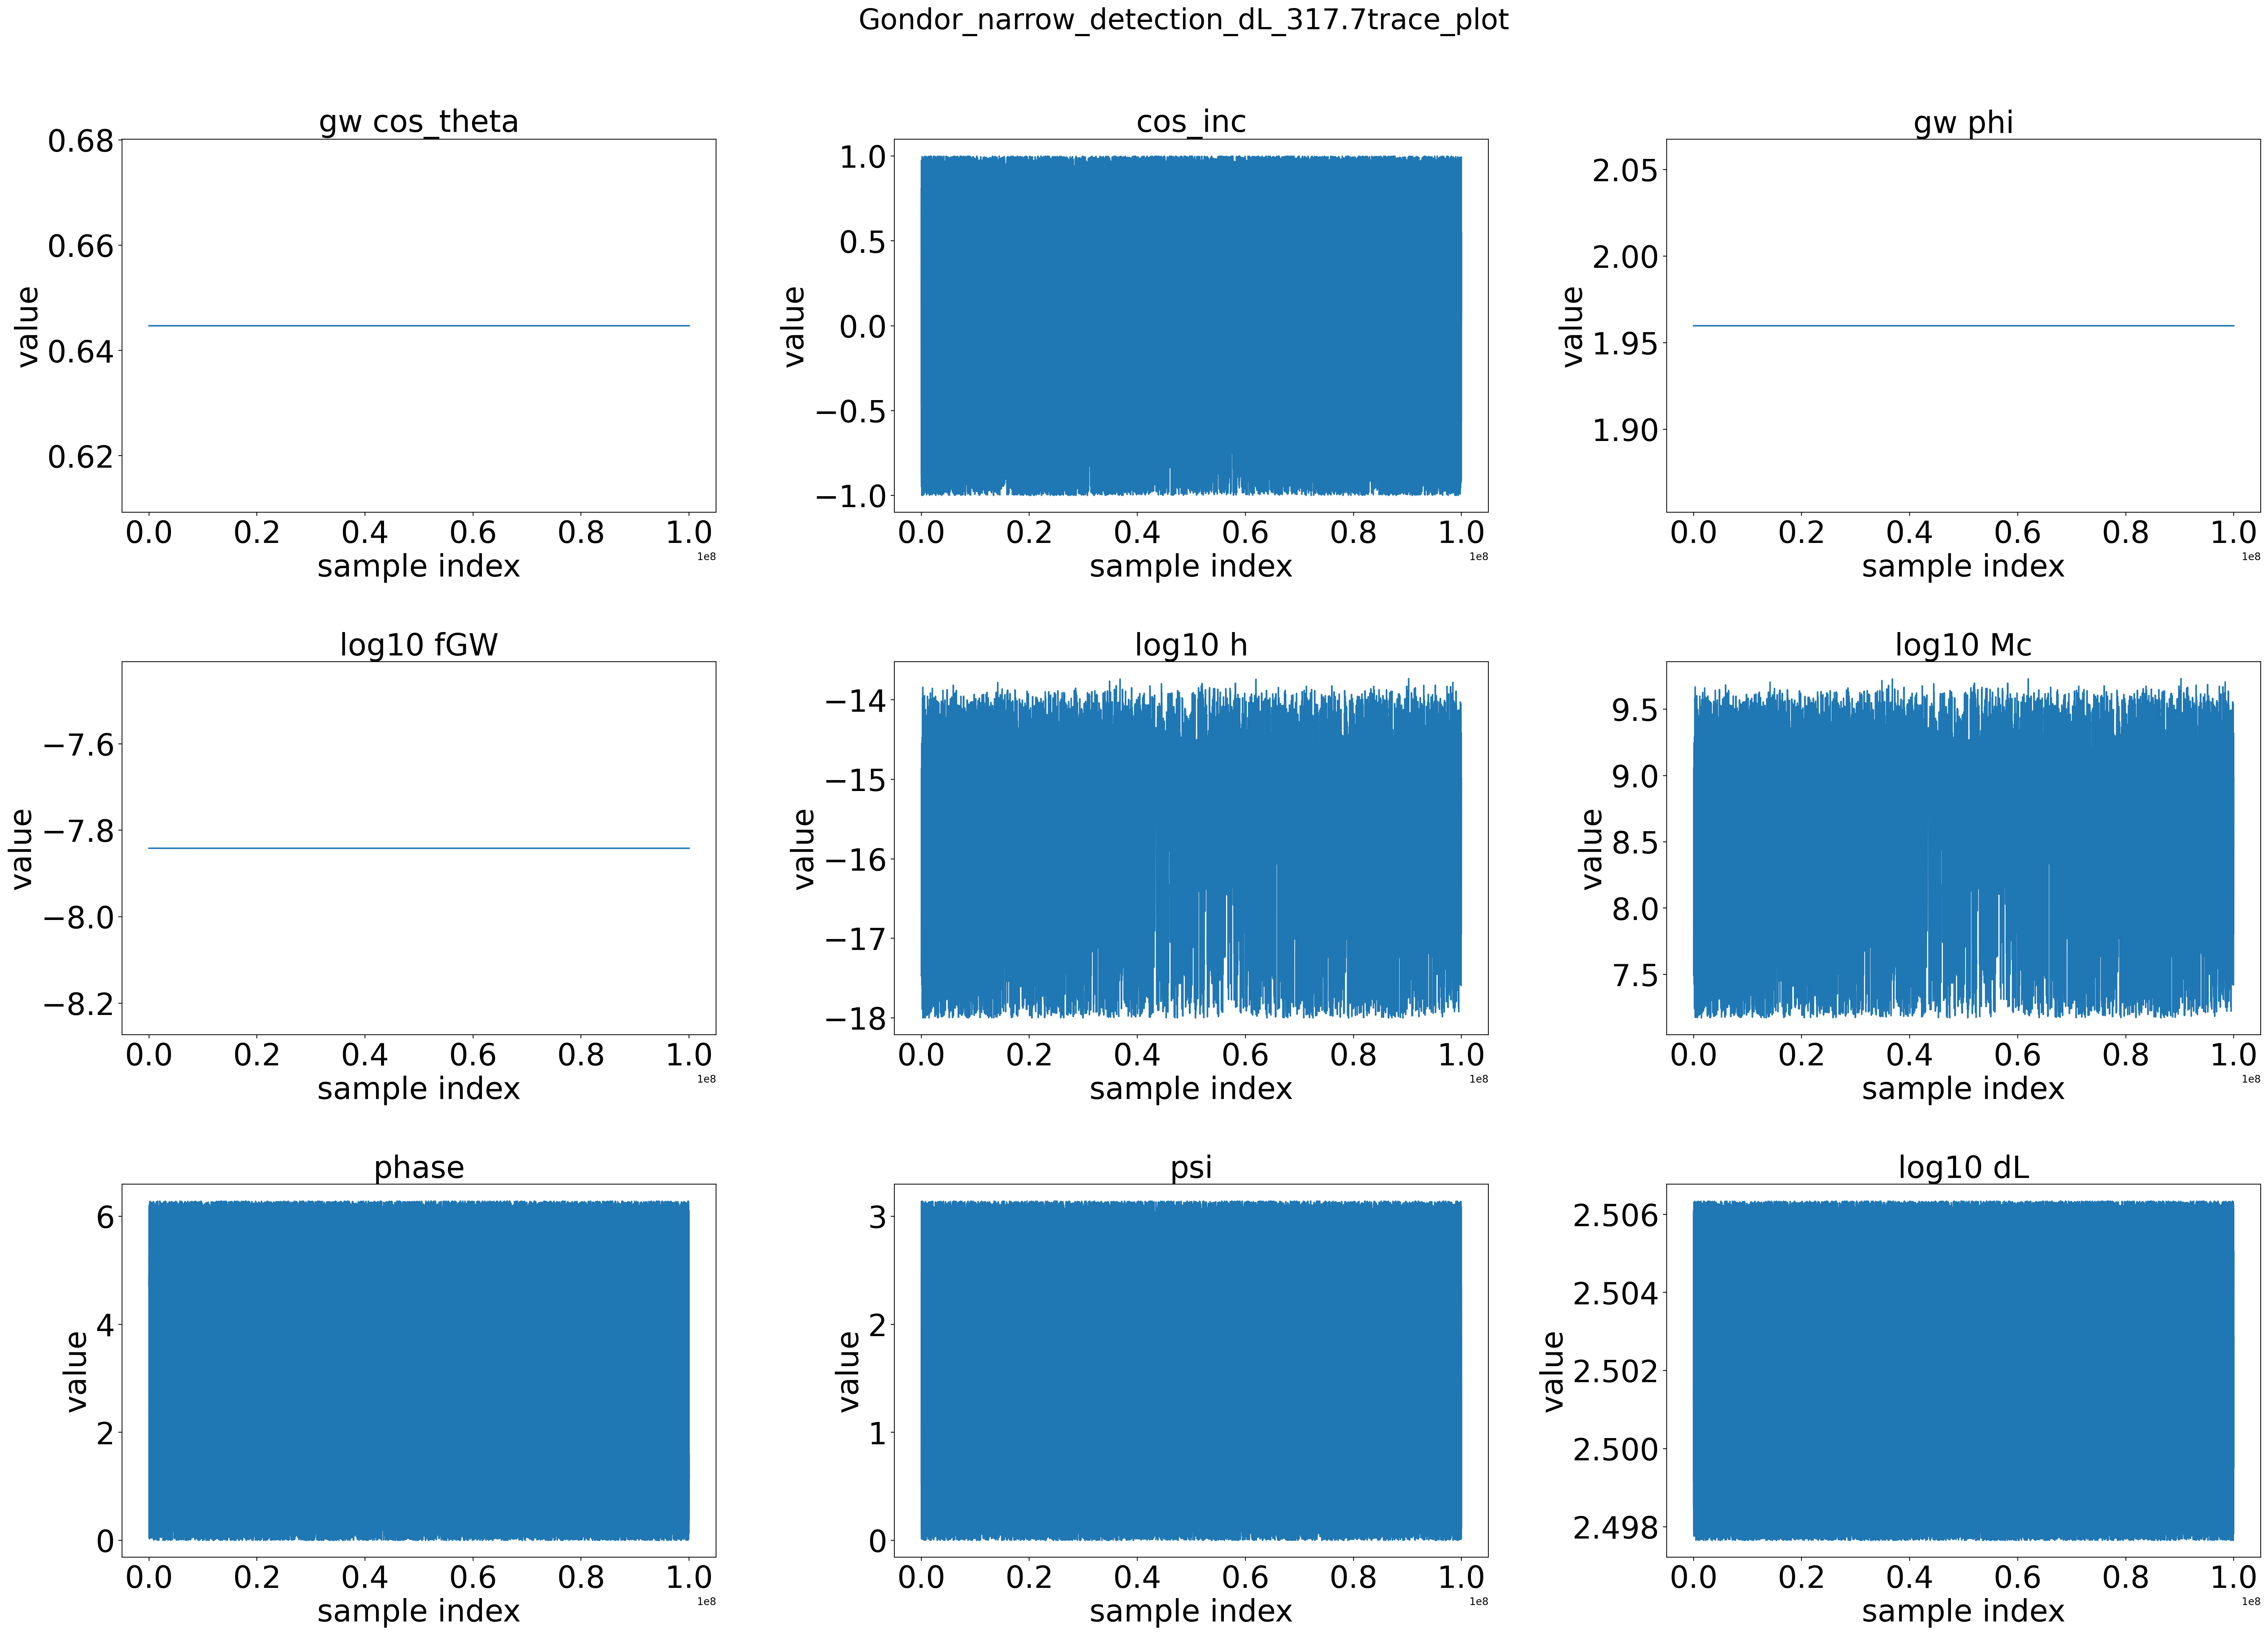

In [11]:
import matplotlib.pyplot as plt

title = ["gw cos_theta", "cos_inc", "gw phi", "log10 fGW", 
         "log10 h", "log10 Mc", "phase", "psi", "log10 dL"]

j = -1
row, column = 3, 3
fig, axs = plt.subplots(row, column, figsize=(30, 20))
fig.tight_layout(h_pad=3, w_pad=2)

# Loop over parameters
for i in range(len(title)): 
    if i % column == 0:
        j += 1
    axs[j, i % column].plot(d_L_mask, samples2plot[d_L_mask, i])
    axs[j, i % column].set_title(title[i], fontsize=30)    # bigger subplot title
    axs[j, i % column].tick_params(axis="both", labelsize=30)  # bigger tick labels
    axs[j, i % column].set_xlabel("sample index", fontsize=30)
    axs[j, i % column].set_ylabel("value", fontsize=30)

# Global title
fig.suptitle(trace_plot_title, fontsize=28, y=1.08)

plt.subplots_adjust(hspace=0.4, wspace=0.3)  # more spacing
#plt.show()
#plt.savefig("trace_plots.png", dpi=200, bbox_inches="tight")


In [12]:
print(np.min(samples2plot[d_L_mask,5]))
print(np.max(np.log10(samples2plot[d_L_mask,5])))

7.1714096e+00
0.9881783


## SD BF

hmin -17.999996
hmax -13.733294
Mc min 7.1714096
Mc max 9.731467
219291


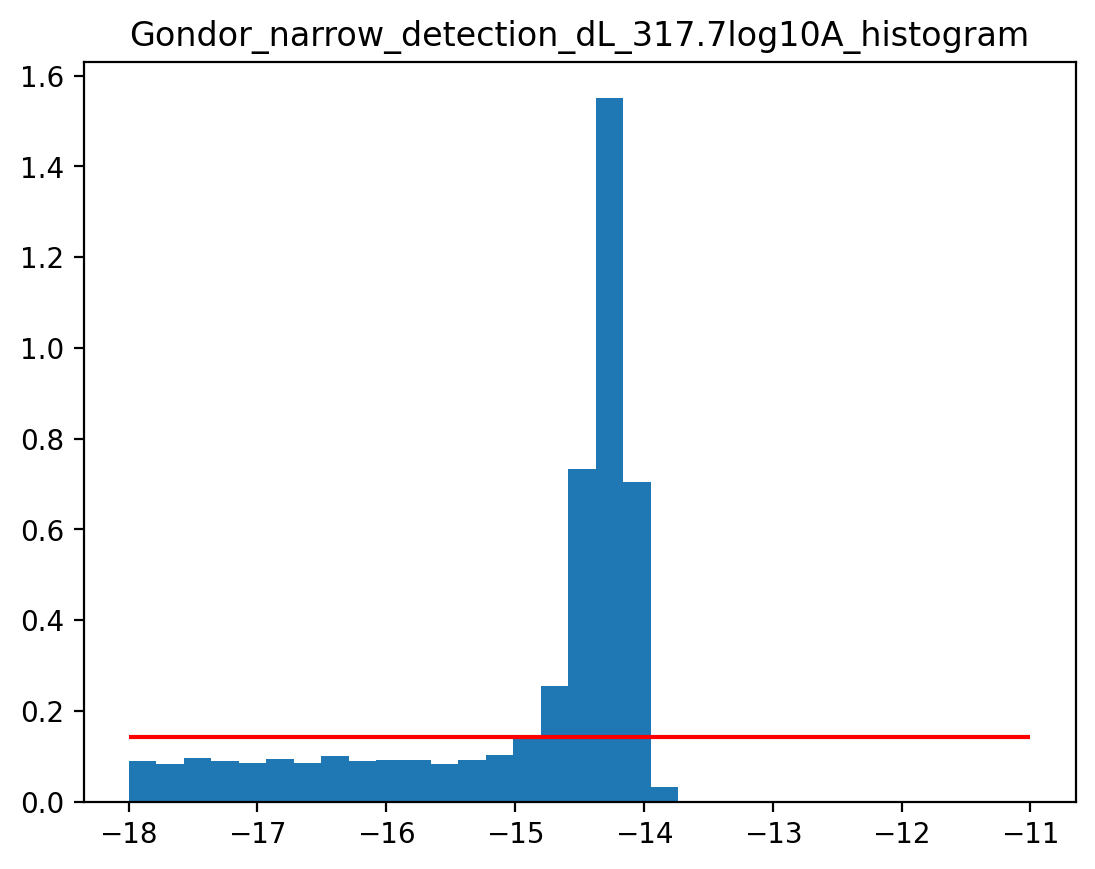

In [13]:
logAmin_dL = np.min(samples2plot[d_L_mask,4])
logAmax_dL = np.max(samples2plot[d_L_mask,4])
print("hmin",logAmin_dL)
print("hmax",logAmax_dL)
print("Mc min",np.min(samples2plot[d_L_mask,5]))
print("Mc max",np.max(samples2plot[d_L_mask,5]))

print(len(samples2plot[d_L_mask,4]))

plt.hist(samples2plot[d_L_mask,4], bins=20, density=True)
plt.hlines(1/(-11 - logAmin_dL), logAmin_dL, -11,  color='red')
plt.title(BF_histogram_title)
plt.show()

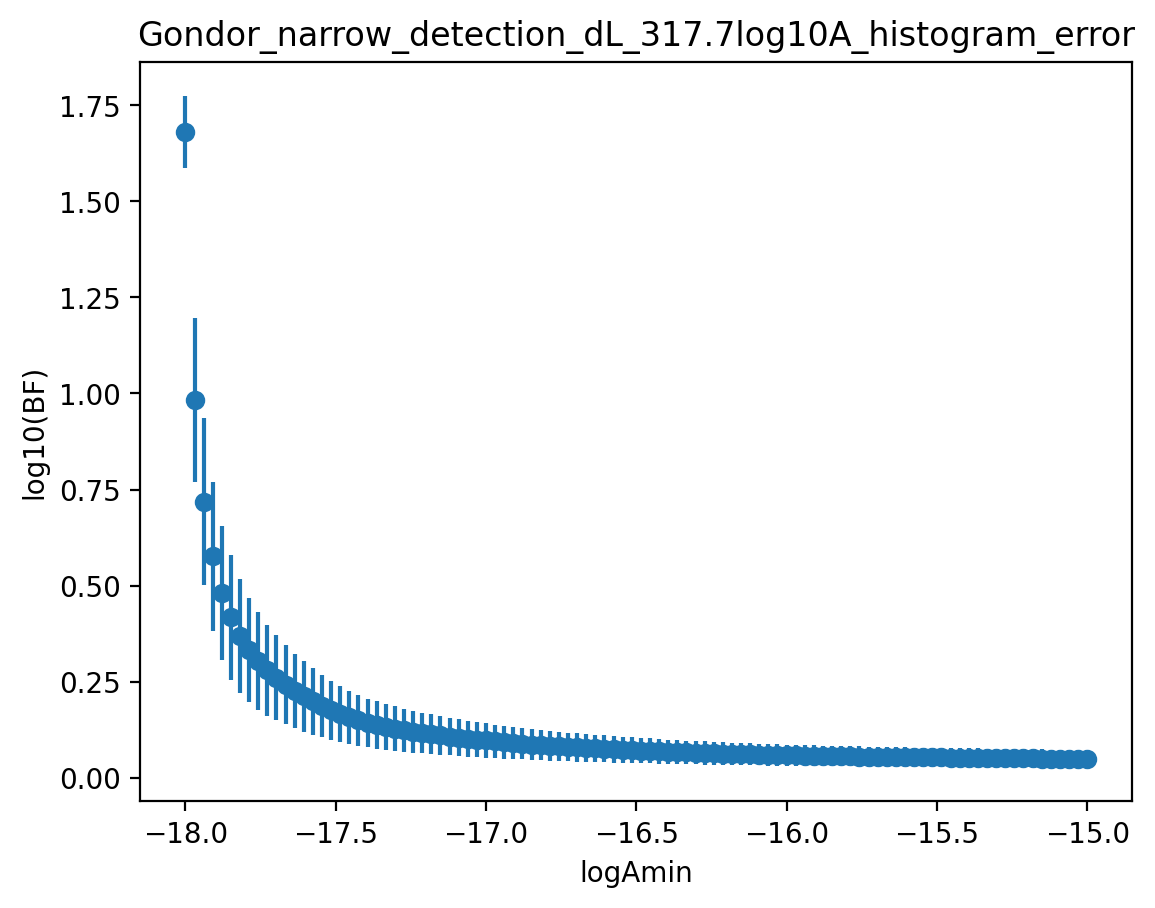

In [14]:
#d_L correlated SD BF
logamins = np.linspace(logAmin_dL, -15, 100)
BF_arr = []
BF_err_arr = []

from enterprise_extensions import model_utils
for logamin in logamins:
    BF,BF_err = model_utils.bayes_fac(samples = samples2plot[d_L_mask,4], logAmin=logamin, logAmax=-11)
    BF_arr.append(BF)
    BF_err_arr.append(BF_err)

plt.errorbar(logamins, BF_arr, yerr=BF_err_arr, fmt='o')
plt.xlabel('logAmin')
plt.ylabel("log10(BF)")
plt.title(BFerr_title)
plt.show()

In [15]:
#d_L correlated SD BF
BF, BF_err = model_utils.bayes_fac(samples=samples2plot[d_L_mask,4], logAmax=-11)
print(f"log10A BF = {BF:.4f} ± {BF_err:.4f}")

log10A BF = 1.6809 ± 0.0932


In [16]:
#Non d_L correlated SD BF
from enterprise_extensions import model_utils
BF,BF_err = model_utils.bayes_fac(samples = samples_cold[0][::10,4], logAmax=-11)
print(f"log10A BF = {BF:.4f} ± {BF_err:.4f}")

log10A BF = 1.0349 ± 0.0038


In [17]:
print(BF_arr[0:10])

[1.6808469012358047, 0.9823886517665741, 0.7183538124310276, 0.5765152345753062, 0.4800948706690036, 0.4172325342218094, 0.3700538779509212, 0.33298229176455224, 0.30446415898776275, 0.2802851902062046]


In [18]:
print(BF_err_arr[0:10])

[0.0932189233524711, 0.21342024916046953, 0.217388342468849, 0.19438034633135903, 0.17466670506756415, 0.1612866287862768, 0.14799620015046455, 0.13475167966298582, 0.12708862127248916, 0.11801225195216429]
